## Test Day with pretty ugly data

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


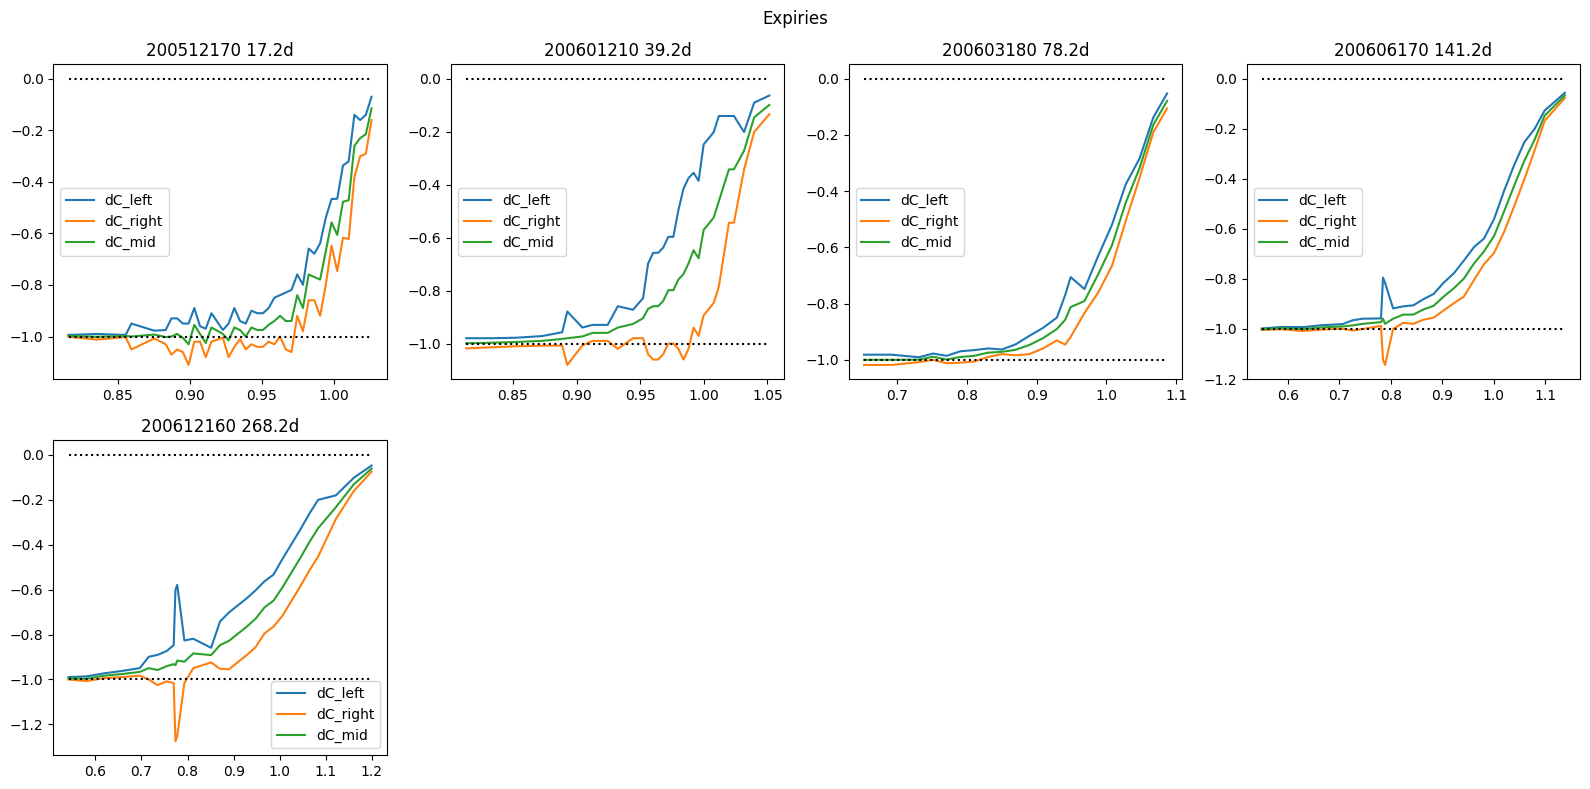

00: SPX 2005-11-21: Generating arb-free price surface.
01:   SPX 2005-11-21: Generated 5 linear arbitrage-free expiries with extended strikes from 5 market expiries. This took 0.048s.             
01:   SPX 2005-11-21: Finding linear arbitrage-free mid prices accross the entire surface of 132 strikes with a minimum strike distance of 0.00397... done. This took 0.026s.
00: SPX 2005-11-21: generated arbitrage-free price surface. Dropped 0 expiries and 36 strikes of the remaining expiries. This took 0.097s.


,spot,spot_prev,date,ticker,call_symbol,put_symbol,call_opt_id,put_opt_id,is_american,is_am,...,pure_fit1_gamma,pure_fit1_vega,pure_fit1_theta,fitX_vol,pure_fitX_price,pure_fitX_delta,pure_fitX_dk,pure_fitX_gamma,pure_fitX_vega,pure_fitX_theta
0,1254.849976,1248.27002,2005-11-21,SPX,SXB.LJ,SXB.XJ,21271691,21271698,False,True,...,0.078038,0.002076,0.005929,0.399989,0.244184,0.996833,-0.995674,0.091927,0.002510,0.007354
1,1254.849976,1248.27002,2005-11-21,SPX,SPQ.LE,SPQ.XE,21308365,21308367,False,True,...,0.211766,0.004588,0.010670,0.313127,0.184554,0.994339,-0.992873,0.197400,0.004219,0.009677
2,1254.849976,1248.27002,2005-11-21,SPX,SPQ.LJ,SPQ.XJ,21271708,21271717,False,True,...,0.284928,0.005625,0.011919,0.283264,0.164678,0.993164,-0.991616,0.257880,0.004986,0.010346
3,1254.849976,1248.27002,2005-11-21,SPX,SPQ.LO,SPQ.XO,21308364,21308366,False,True,...,0.394474,0.007037,0.013473,0.255363,0.144817,0.991220,-0.989502,0.356524,0.006214,0.011625
4,1254.849976,1248.27002,2005-11-21,SPX,SPQ.LP,SPQ.XP,29437918,29437917,False,True,...,0.427075,0.007476,0.014045,0.249631,0.140845,0.990779,-0.989030,0.380698,0.006486,0.011862
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153,1254.849976,1248.27002,2005-11-21,SPX,SXG.LO,SXG.XO,30580045,30580044,False,True,...,2.964369,0.372337,0.020644,0.114961,0.023355,0.321795,-0.280524,3.022343,0.369788,0.019972
154,1254.849976,1248.27002,2005-11-21,SPX,SXG.LA,SXG.XA,23948246,23948249,False,True,...,2.794842,0.339720,0.018228,0.110589,0.016934,0.259945,-0.224344,2.842807,0.334592,0.017384
155,1254.849976,1248.27002,2005-11-21,SPX,SXG.LS,SXG.XS,23948248,23948239,False,True,...,2.221949,0.254335,0.012851,0.104296,0.008304,0.155013,-0.130769,2.214771,0.245842,0.012046
156,1254.849976,1248.27002,2005-11-21,SPX,SYZ.LT,SYZ.XT,23948257,23948256,False,True,...,1.496031,0.162154,0.007758,0.099790,0.003664,0.081499,-0.067065,1.464468,0.155535,0.007292


In [2]:
if False:
    import os
    os.environ["QUANTDATA_CACHE_MODE"] = "off" # turns off global cache mode; good for testing, but do not use in general.

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.sanos.arbfree
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree

from datetime import date

from cdxcore.dynaplot import figure
from quantdata.widb.day import collect_raw_day, enrich_day, ExpiryFilter, RawDayFilter
from quantdata.widb.arbfree import mk_arb_free_day, MkArbFree
from quantdata.biz_calendar import next_business_day, DAYS_PER_YEAR
from cdxcore.verbose import Context
from IPython.display import display
import numpy as np

def test():
    ticker = "SPX"
    d      = next_business_day( date(2005, 11, 21), count_start=True )

    raw_day_filter = RawDayFilter()
    expiry_filter = ExpiryFilter()
    verbose = Context.all

    raw_day = collect_raw_day(ticker, d, raw_day_filter=raw_day_filter, verbose=verbose, raise_if_bad_day=False)

    enr_day = enrich_day(ticker, d, raw_day, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad_day=False)

    expiry_ids = enr_day['expiry_id'].to_numpy()
    unids = np.unique( expiry_ids )
    with figure("Expiries", row_size=4, col_size=4, columns=4) as fig:
        for uid in unids:
            tte_y = enr_day['tte_y'][ expiry_ids == uid ].iloc[0]
            ax = fig.add_subplot(f"{uid} {tte_y*DAYS_PER_YEAR:.1f}d")

            mask = enr_day['expiry_id'] == uid
            strikes = enr_day['pure_strike'][mask].to_numpy()
            bids = enr_day['pure_bid_price'][mask].to_numpy()
            asks = enr_day['pure_ask_price'][mask].to_numpy()
            mids = (bids + asks) / 2.

            dC_left = ( asks[1:] - bids[:-1] ) / ( strikes[1:] - strikes[:-1] )
            dC_right = ( asks[:-1] - bids[1:] ) / ( strikes[:-1] - strikes[1:] )
            dC_mid = ( mids[1:] - mids[:-1] ) / ( strikes[1:] - strikes[:-1] )

            ax.plot(strikes[1:], dC_left, label="dC_left")
            ax.plot(strikes[1:], dC_right, label="dC_right")
            ax.plot(strikes[1:], dC_mid, label="dC_mid")
            ax.plot(strikes[1:], strikes[1:]*0-1., ":", color="black")
            ax.plot(strikes[1:], strikes[1:]*0, ":", color="black")
            ax.legend()

    arb_free = MkArbFree()
    arb_free = mk_arb_free_day(ticker, d, enr_day, mk_arb_free=arb_free, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad_day=False, override_cache_mode="off")

    display(arb_free)
    return arb_free

_ = test()